# **Ejercicio 2: Entregable Final (videogames_reviews.csv)**

Vamos a trabajar con un dataframe que contiene información sobre reseñas de videojuegos. Cada fila del dataframe contiene la información de una reseña, y las columnas son las siguientes:
- Contenido: texto de la reseña
- Valoración: Recomendado o No recomendado
- Recomendado binario: 1 si la valoración es Recomendado, 0 si la valoración es No recomendado
  
El objetivo de este ejercicio es conseguir extraer información valiosa de las reseñas de un dataset más 'crudo' o que necesita un preprocesado mayor que el del ejercicio 1.

1. **Filtramos por las 100 reseñas con el contenido más largo**. Esto ya os lo doy hecho más abajo.
2. En el DataFrame resultante, habremos obtenido muchas filas en las que realmente el contenido de la reseña no es nada relevante. **Instruir vía Prompting a un LLM para que filtre las filas del DataFrame que de verdad aportan información de la que se pueden extraer insights relevantes**
3. **Paso final:** extraer información relevante de este último dataframe doblemente filtrado usando un segundo LLM. Por ejemplo, un json final como este:

    ```json
    {
    "Id": "{{id}}",
    "SentimientoGeneral": "Positivo|Negativo|Neutral",
    "AspectosPositivos": "[lista de aspectos positivos mencionados]",
    "AspectosNegativos": "[lista de aspectos negativos mencionados]",
    "Dificultad": "Demasiado Fácil|Fácil|Equilibrado|Difícil|Demasiado Difícil|No Mencionado",
    "Recomendado": "{{recomendado}}"
    }
    ```

**Consideraciones adicionales:**

- También tienes un csv de ejemplo de resultado final (analisis_videojuegos_resultados.csv) donde se han extraído otras entidades y se ha entregado otro formato. **Esto es a libre elección, pero un mínimo de 3 entidades extraídas** por el segundo LLM.
- Los modelos suelen ser buenos realizando tareas de una en una. Por eso separamos en dos pasos el filtrado de contenido relevante y el de extracción de ese contenido.
- Puedes usar cualquier proveedor y canal: vía API (como Groq/Gemini) o en local vía HuggingFce teniendo en cuenta las limitaciones y ventajas de cada uno, rate limits del modelo elegido, tamaño...
- Tener en cuenta qué cantidad de tokens/información/tareas le estamos pasando al LLM en cada llamada comparándolo con los límites que tenemos para el LLM elegido
- Se valorará **justificar cada elección** como: cada time.stop() añadido, cada lote de filas de DataFrame que pasemos en cada llamada... etc ajustándonos como digo a esos límites que tenemos.

In [ ]:
!pip install -q -U transformers accelerate bitsandbytes

In [ ]:
import pandas as pd
from google.colab import drive, files
import torch
import json
import re
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import gc

In [ ]:
# leemos csv desde drive
# debe estar en la carpeta 'Prompt_Engineering'
drive.mount("/content/drive")
data = pd.read_csv("/content/drive/MyDrive/Prompt_Engineering/videogames_reviews.csv")
data

Mounted at /content/drive


,Unnamed: 0,Contenido,Valoración,Recomendado_binario
0,0,2 marzo so bad,No recomendado,0
1,1,10 febrero actualmente recomiendo juego contab...,No recomendado,0
2,2,9 febrero increíblemente gracioso ver cómo cdp...,No recomendado,0
3,3,the world in this game is extremely static the...,No recomendado,0
4,4,zero replayability i finished this game in abo...,No recomendado,0
...,...,...,...,...
19995,19995,si,Recomendado,1
19996,19996,cojonudo,Recomendado,1
19997,19997,reostia historia guapisima graficos impresiona...,Recomendado,1
19998,19998,basicamente sublime obra maestra,Recomendado,1


In [ ]:
# Análisis exploratorio básico
print("Información básica del dataframe:")
print(f"Forma del dataframe: {data.shape}")
print(f"Columnas: {list(data.columns)}")
print("\nTipos de datos:")
print(data.dtypes)
print("\nPrimeras filas:")
data.head()

Información básica del dataframe:
Forma del dataframe: (20000, 4)
Columnas: ['Unnamed: 0', 'Contenido', 'Valoración', 'Recomendado_binario']

Tipos de datos:
Unnamed: 0              int64
Contenido              object
Valoración             object
Recomendado_binario     int64
dtype: object

Primeras filas:


,Unnamed: 0,Contenido,Valoración,Recomendado_binario
0,0,2 marzo so bad,No recomendado,0
1,1,10 febrero actualmente recomiendo juego contab...,No recomendado,0
2,2,9 febrero increíblemente gracioso ver cómo cdp...,No recomendado,0
3,3,the world in this game is extremely static the...,No recomendado,0
4,4,zero replayability i finished this game in abo...,No recomendado,0


In [ ]:
# Análisis de valores nulos y únicos
print("Valores nulos por columna:")
print(data.isnull().sum())
print("\nValores únicos en 'Valoración':")
print(data['Valoración'].value_counts())
print("\nEstadísticas de la columna 'Recomendado_binario':")
print(data['Recomendado_binario'].value_counts())

Valores nulos por columna:
Unnamed: 0               0
Contenido              288
Valoración               0
Recomendado_binario      0
dtype: int64

Valores únicos en 'Valoración':
Valoración
No recomendado    10000
Recomendado       10000
Name: count, dtype: int64

Estadísticas de la columna 'Recomendado_binario':
Recomendado_binario
0    10000
1    10000
Name: count, dtype: int64


## **PASO 1**
Obtener los 100 comentarios con más texto para análisis posterior.

In [ ]:
# Preprocesamiento simplificado: Top 100 comentarios con más texto
print("Preprocesando datos para obtener los 100 comentarios más largos...")

# Eliminar filas con contenido nulo
df_limpio = data.dropna(subset=['Contenido']).copy()
print(f"Comentarios válidos (sin nulos): {len(df_limpio)}")

# Eliminamos filas con 'Contenido' duplicado
df_limpio = df_limpio.drop_duplicates(subset=['Contenido'])

# Calcular longitud de caracteres
df_limpio['longitud_caracteres'] = df_limpio['Contenido'].str.len()

# Seleccionar los 100 comentarios más largos
df_top_100 = df_limpio.nlargest(100, 'longitud_caracteres').reset_index(drop=True)

# Eliminar columnas innecesarias
if 'Unnamed: 0' in df_top_100.columns:
    df_top_100 = df_top_100.drop('Unnamed: 0', axis=1)

print(f"\nDataset final: {len(df_top_100)} comentarios")
print(f"Longitud promedio: {df_top_100['longitud_caracteres'].mean():.1f} caracteres")
print(f"Longitud mínima: {df_top_100['longitud_caracteres'].min()} caracteres")
print(f"Longitud máxima: {df_top_100['longitud_caracteres'].max()} caracteres")

print("\nDistribución de valoraciones en el top 100:")
print(df_top_100['Valoración'].value_counts())

# Mostrar el dataframe resultante
df_top_100

Preprocesando datos para obtener los 100 comentarios más largos...
Comentarios válidos (sin nulos): 19712

Dataset final: 100 comentarios
Longitud promedio: 6451.7 caracteres
Longitud mínima: 5121 caracteres
Longitud máxima: 7972 caracteres

Distribución de valoraciones en el top 100:
Valoración
No recomendado    63
Recomendado       37
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Contenido,Valoración,Recomendado_binario,longitud_caracteres
0,suiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiii...,Recomendado,1,7972
1,this was probably my first preorder i felt tha...,Recomendado,1,7662
2,oh well admittedly its difficult for to write ...,No recomendado,0,7638
3,i know many will handwave away any criticisms ...,No recomendado,0,7609
4,i had enormous expectations having put thousan...,No recomendado,0,7609
...,...,...,...,...
95,después muchísimas muertes conseguí acabarlo d...,No recomendado,0,5237
96,first off i wasnt hyped for the game at the be...,No recomendado,0,5210
97,is it buggy as they say yes and nothing too se...,Recomendado,1,5179
98,dios hecho juego debería existirjugabilidad co...,Recomendado,1,5167


## **Paso 2:**
Desacargar el modelo desde Hugging Face con tamaño reducido en local

In [ ]:
# modelo elegido
MODEL_ID = "Qwen/Qwen3-1.7B"
# numero máximo de tokens de entrada
MAX_INPUT_TOKENS = 8192

In [ ]:
# configuración de la cuantización
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

# tokenizador
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# modelo
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto"
)

print("Modelo cargado correctamente")
print(f"Memoria del modelo: {model.get_memory_footprint() / 1e9:.2f} GB")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Modelo cargado correctamente
Memoria del modelo: 1.33 GB


## **Paso 3: Filtrado de reseñas**

Se utiliza una salida binaria 'SI' o 'NO' para determinar si cada reseña contiene información relevante.

Se procesan de una en una ya que al intentar procesar varias en una misma llamada el modelo no respondía bien.

In [ ]:
filtering_system_instruction = """
  Tu tarea es identificar qué reseñas contienen información útil para
  un análisis posterior.
  Solo puedes responder 'SI' o 'NO'.
  Vas a recibir una reseña, indica 'SI' si contiene información relevante y
  'NO' si no contiene información relevante.

  CRITERIOS:
  - RELEVANTE: contiene opiniones, críticas o experiencias concretas sobre
    el videojuego, como jugabilidad, historia, gráficos, rendimiento,
    dificultad, mecánicas o contenido.
  - IRRELEVANTE: contiene únicamente spam, repeticiones sin sentido,
    caracteres aleatorios, publicidad o expresiones genéricas sin
    información útil sobre el videojuego.

  REGLAS:
  1. La longitud de una reseña NO determina su relevancia.
  2. Conserva tanto las opiniones positivas como las negativas.
  3. No clasifiques una reseña como relevante solo porque mencione un videojuego.
  4. No presupongas que las reseñas son relevantes.

  EJEMPLO 1:
  Entrada:
    [
      {"id": 1, "Contenido": "Amazing graphics but terrible performance}
    ]
  Salida:
    SI

  EJEMPLO 2:
  Entrada:
    [
      {"id": 2, "Contenido": "nooooo"},
    ]
  Salida:
    NO
"""

En este caso, en la llamada al modelo no le pasamos parámetros porque buscamos un comportamiento determinista, no queremos creatividad.

In [ ]:
def delete_meaningless_lines(df_top_100: pd.DataFrame) -> pd.DataFrame:
  """función para que el modelo elimine filas sin valor
  Args:
    - df_top_100: 100 reseñas propuestas para analizar
    - batch_size: número de reseñas de cada iteración
  Returns:
    lista de reseñas que tienen valor para el análisis
  """
  # añadimos cabecera a columna de ids
  df_top_100 = df_top_100.reset_index(names="id")
  # lista para guardar filas relevantes
  good_lines_ids: list[int] = []
  # bucle de 0 a tamaño de dataframe
  for i in range(0, len(df_top_100)):

    # guardamos fila
    df_batch = df_top_100.iloc[[i]]

    msg = [
        {"role": "system", "content": filtering_system_instruction},
        {"role": "user", "content": df_batch.to_json(orient="records")}
    ]

    # aplicamos plantilla de chat a msg
    prompt = tokenizer.apply_chat_template(
        msg,
        tokenize=False,               # devuelve texto, no IDs
        add_generation_prompt=True,   # añade al final el inicio del turno del asistente
        enable_thinking=False         # sin razonamiento previo: respuesta directa
    )

    # tokenizamos prompt
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    # comprobamos que no superamos el límite de tokens de entrada
    if inputs["input_ids"].shape[-1] > MAX_INPUT_TOKENS:
      print(f"Lote {i}: supera el límite de tokens")
      continue

    # llamada al modelo
    output = model.generate(
        **inputs,
        max_new_tokens=100,           # limitamos creación de nuevos tokens a 100
        do_sample=False
    )

    # quitamos tokens del prompt y decodificamos
    response = tokenizer.decode(
        output[0][inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True
    )
    print(f"Batch {i}:")
    print(f"Respuesta del modelo: {repr(response)}")
    print(f"IDs disponibles: {df_batch['id'].tolist()}")

    if response.strip().upper() in ("SI", "SÍ"):
      # si respuesta es 'SI' guardamos id de fila
      good_lines_ids.extend(df_batch["id"].tolist())
  # devuelve df con filas relevantes
  return df_top_100.iloc[good_lines_ids]

In [ ]:
# Limpiar memoria caché de la GPU antes de ejecutar
gc.collect()
torch.cuda.empty_cache()
# llamamos a funcion para eliminar filas sin sentido
df_filtered = delete_meaningless_lines(df_top_100)
df_filtered

Batch 0:
Respuesta del modelo: 'NO'
IDs disponibles: [0]
Batch 1:
Respuesta del modelo: 'SI'
IDs disponibles: [1]
Batch 2:
Respuesta del modelo: 'SI'
IDs disponibles: [2]
Batch 3:
Respuesta del modelo: 'SI'
IDs disponibles: [3]
Batch 4:
Respuesta del modelo: 'SI'
IDs disponibles: [4]
Batch 5:
Respuesta del modelo: 'SI'
IDs disponibles: [5]
Batch 6:
Respuesta del modelo: 'SI'
IDs disponibles: [6]
Batch 7:
Respuesta del modelo: 'SI'
IDs disponibles: [7]
Batch 8:
Respuesta del modelo: 'SI'
IDs disponibles: [8]
Batch 9:
Respuesta del modelo: 'SI'
IDs disponibles: [9]
Batch 10:
Respuesta del modelo: 'SI'
IDs disponibles: [10]
Batch 11:
Respuesta del modelo: 'SI'
IDs disponibles: [11]
Batch 12:
Respuesta del modelo: 'SI'
IDs disponibles: [12]
Batch 13:
Respuesta del modelo: 'SI'
IDs disponibles: [13]
Batch 14:
Respuesta del modelo: 'SI'
IDs disponibles: [14]
Batch 15:
Respuesta del modelo: 'SI'
IDs disponibles: [15]
Batch 16:
Respuesta del modelo: 'SI'
IDs disponibles: [16]
Batch 17:
Respues

,id,Contenido,Valoración,Recomendado_binario,longitud_caracteres
1,1,this was probably my first preorder i felt tha...,Recomendado,1,7662
2,2,oh well admittedly its difficult for to write ...,No recomendado,0,7638
3,3,i know many will handwave away any criticisms ...,No recomendado,0,7609
4,4,i had enormous expectations having put thousan...,No recomendado,0,7609
5,5,i finished the witcher 3 for the first time th...,Recomendado,1,7604
...,...,...,...,...,...
95,95,después muchísimas muertes conseguí acabarlo d...,No recomendado,0,5237
96,96,first off i wasnt hyped for the game at the be...,No recomendado,0,5210
97,97,is it buggy as they say yes and nothing too se...,Recomendado,1,5179
98,98,dios hecho juego debería existirjugabilidad co...,Recomendado,1,5167


##**Paso 4:**
Quitamos y_true del df para evaluación

Para evaluar como razona el modelo se quitan las variables que indican si se recomienda el videojuego para utilizarlo posteriormente como referencia.

In [ ]:
y_true = df_filtered["Recomendado_binario"] # 0 = No, 1 = Sí
df_filtered = df_filtered.drop(columns=["Valoración", "Recomendado_binario"])

## **Paso 5: Extracción de información**
Se utiliza una salida JSON estructurada con cuatro atributos: identificador, sentimiento general, dificultad y recomendación. Este formato permite organizar los resultados en un DataFrame y comparar la recomendación predicha con la etiqueta real del dataset.

Evitamos `AspectosPositivos` y `AspectosNegativos` ya que provocaban alucianciones en el modelo y no respondía coherentemente.

Se utiliza batch_size=2 para procesar dos reseñas por llamada, reduciendo el número de ejecuciones y aprovechando mejor los recursos disponibles, sin sobrecargar la memoria GPU.

In [ ]:
extraction_system_instruction = """
  Eres un analista de reseñas de videojuegos.
  Debes devolver un JSON con estos atributos:
  - Id: identificador original.
  - SentimientoGeneral: sentimiento percibido en la reseña.
    Valores permitidos: "Positivo", "Negativo" o "Neutral".
  - Dificultad: dificultad indicada por el usuario.
    Valores permitidos: "Demasiado Fácil", "Fácil", "Equilibrado",
    "Difícil", "Demasiado Difícil" o "No Mencionado" en caso de que
    no diga nada sobre la dificultad.
  - Recomendado:
    1 si crees que el usuario recomienda el juego.
    0 si crees que el usuario no recomienda el juego.
    Valores permitidos: 0 o 1

  Para determinar "Recomendado", prioriza la conclusión
  del autor y sus declaraciones explícitas de recomendación
  sobre el número de críticas positivas o negativas.
  Una reseña con muchas críticas puede recomendar el juego.

  REGLAS:
  1. Analiza cada reseña individualmente utilizando solo su contenido.
    No te inventes nada.
  2. El sentimiento y la recomendación las marca tu sensación sobre
    la reseña.
  3. No confundas sentimiento negativo con ausencia de recomendación.
  4. La dificultad se refiere exclusivamente al propio juego.
    La dificultad no son bugs, problemas técnicos o críticas negativas.
  5. Si no habla de la dificultad, devuelve "No Mencionado".
  6. Conserva los IDs originales y el orden de las reseñas.
  7. Devuelve únicamente un array JSON válido, sin Markdown ni explicaciones.

  EJEMPLO:
  [
    {
      "Id": 1,
      "SentimientoGeneral": "Positivo",
      "Dificultad": "Difícil",
      "Recomendado": 1
    }
  ]
"""

En este caso en la llamada al modelo se le pasan parámetros indicados por el proveedor como los parámetros óptimos para este modelo:
- `max_new_tokens = 1024`: limita número máximo de tokens que puede generar el modelo por respuesta
- `do_sample = True`: activa la selección probabilística de tokens en lugar de elegir siempre el más probable
- `temperature = 0.7`: controla la aleatoriedad de las respuestas, equilibrando creatividad y coherencia
- `top_p = 0.8`: limita la selección al conjunto mínimo de tokens cuya probabilidad acumulada alcanza al menos el 80 %
- `top_k = 20`: limita la selección a los 20 tokens más probables


In [ ]:
def clean_and_load_json(response_str):
  """Limpia y corrige errores comunes de formato JSON en las respuestas."""
  clean_str = response_str.strip()
  # Eliminar bloques de código markdown si existen
  if clean_str.startswith("```"):
      clean_str = clean_str.split("\n", 1)[-1]
      if clean_str.endswith("```"):
          clean_str = clean_str[:-3]
  clean_str = clean_str.strip()

  try:
      return json.loads(clean_str)
  except json.JSONDecodeError as e:
      # Si falla, intentamos una limpieza manual de comillas e imperfecciones comunes
      try:
        # Buscar la estructura de lista [...] que contiene la información
        match = re.search(r'\[\s*\{.*\}\s*\]', clean_str, re.DOTALL)
        if match:
          return json.loads(match.group(0))
      except:
          pass
      raise e

def extract_relevant_info(df: pd.DataFrame, batch_size: int = 2) -> list[dict]:
  """Extrae información requerida sobre las reseñas
  Args:
    - df:
    - batch_size:
  Returns:
    lista de json con la info relevante de cada reseña
  """
  # lista de respuestas del modelo
  relevant_info = []
  # bucle de 0 a tamaño de dataframe, avanza 'batch_size' posiciones en cada iter
  for i in range(0, len(df), batch_size):
    # guardamos df de tamaño 'batch_size'
    df_batch = df.iloc[i:i+batch_size]
    msg = [
      {"role": "system", "content": extraction_system_instruction},
      {"role": "user", "content": df_batch.to_json(orient="records")}
    ]
    # aplicamos plantilla de chat a msg
    prompt = tokenizer.apply_chat_template(
        msg,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )
    # tokenizamos prompt
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    # comprobamos que no superamos el límite de tokens de entrada
    if inputs["input_ids"].shape[-1] > MAX_INPUT_TOKENS:
      print(f"Lote {i}: supera el límite de tokens")
      continue
    # llamamos al modelo
    output = model.generate(
        **inputs,
        max_new_tokens=1024,
        do_sample=True,
        temperature=0.7,
        top_p=0.8,
        top_k=20
    )
    # quitamos tokens del prompt y decodificamos
    response = tokenizer.decode(
        output[0][inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True
    )

    try:
        parsed = clean_and_load_json(response)
        print("-"*80)
        print("ID", df_batch["id"].tolist())
        print("-"*80)
        print(response)
        relevant_info.extend(parsed)
    except Exception as e:
        print(f"Error en batch que inicia en índice {i}: {e}")
        print(f"Respuesta cruda del modelo: {repr(response)}")
  return relevant_info

relevant_info = extract_relevant_info(df_filtered, batch_size=2)

--------------------------------------------------------------------------------
ID [1, 2]
--------------------------------------------------------------------------------
[
  {
    "Id": 1,
    "SentimientoGeneral": "Positivo",
    "Dificultad": "Equilibrado",
    "Recomendado": 1
  },
  {
    "Id": 2,
    "SentimientoGeneral": "Negativo",
    "Dificultad": "Demasiado Difícil",
    "Recomendado": 0
  }
]
--------------------------------------------------------------------------------
ID [3, 4]
--------------------------------------------------------------------------------
[
  {
    "Id": 3,
    "SentimientoGeneral": "Negativo",
    "Dificultad": "Demasiado Difícil",
    "Recomendado": 0
  },
  {
    "Id": 4,
    "SentimientoGeneral": "Negativo",
    "Dificultad": "Demasiado Difícil",
    "Recomendado": 0
  }
]
--------------------------------------------------------------------------------
ID [5, 6]
--------------------------------------------------------------------------------
[
  

##**Paso 6:**
Evaluación de detección de recomendación con métricas de scikit-learn

In [ ]:
# sacamos y_pred de la respuesta del modelo
y_pred = [review["Recomendado"] for review in relevant_info]
# calculamos accuracy, precission, recall, f1-score
print("Accuracy:", accuracy_score(y_true, y_pred))
print("\nClassification report:")
print(classification_report(y_true, y_pred))


Accuracy: 0.826530612244898

Classification report:
              precision    recall  f1-score   support

           0       0.80      0.97      0.88        62
           1       0.91      0.58      0.71        36

    accuracy                           0.83        98
   macro avg       0.86      0.78      0.79        98
weighted avg       0.84      0.83      0.82        98



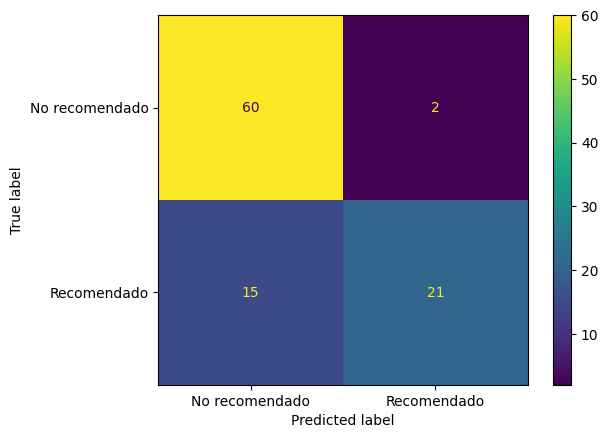

In [ ]:
# mostramos matriz de confusión
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=['No recomendado', 'Recomendado']
)
disp.plot()
plt.show()

## **Documentación**

### **Hugging Face**

Elegido porque ofrece modelos de código abierto o pesos abiertos que podemos descargar, ejecutar y cuantizar sin depender de APIs externas. Además, en móduls anteriores ya hemos trabajado con modelos mediante API y he querido probar esta opción.

### **Modelo `Qwen3-1.7B`**

Elegido por ser un modelo relativamente ligero, multilingüe y preparado para seguir instrucciones, adecuado para tareas de clasificación y extracción de información.

#### **Cuantización a 4 bits**

Llevada a cabo para reducir el consumo de memoria GPU permitiendo ejecutar el modelo en Google Colab con recursos limitados.

Pasamos de 3,4 GB (16 bits) a 1,33 GB (4 bits)

Fórmula aproximada `model_size * tensor_type / 8`

### **Evaluación de los resultados**

El modelo Qwen3-1.7B cuantizado a 4 bits ha obtenido una **accuracy del 82,65 %** sobre 98 reseñas, mostrando un rendimiento satisfactorio en la clasificación de recomendaciones.

El modelo identifica correctamente 60 de las 62 reseñas no recomendadas (recall del 97 %), mientras que solo reconoce 21 de las 36 recomendadas (recall del 58 %). Esto evidencia una **tendencia a clasificar las reseñas como negativas**, generando 15 falsos negativos frente a únicamente 2 falsos positivos.

Este comportamiento puede explicarse por la subjetividad de la variable analizada. Muchas reseñas contienen críticas importantes sobre el videojuego, pero sus autores terminan recomendándolo. El modelo otorga mucho peso a los aspectos negativos mencionados. Tras hacer numerosas pruebas con distintos prompts y distintos parámetros, consideramos esta una buena configuración del modelo.

En conclusión, aunque los resultados son razonablemente buenos para un modelo ligero y cuantizado, existen limitaciones para interpretar opiniones mixtas y recomendaciones implícitas o condicionadas.